# Industrial Surface Defect Segmentation — SegFormer-B2 / U-Net — T3 2026

End-to-end Kaggle notebook: data loading → RLE decode → stratified split → U-Net training (AMP) →
per-class threshold / min-area tuning on the **competition metric** → TTA inference → `submission.csv`.

**Before running (Kaggle notebook settings):**
1. *Add Input* → the competition dataset.
2. *Accelerator* → **GPU T4 x2** (or P100).
3. *Internet* → **On** (downloads the pretrained SegFormer / ResNet weights; if Internet is off the notebook still runs, but from random weights and the score will be much lower).
4. (Optional) *Add-ons → Secrets* → add `WANDB_API_KEY` to log the run to Weights & Biases.

Then **Save Version → Save & Run All**. Total run time ≈ `time_budget_min` (training) + ~10 min (tuning + inference).
Stop any interactive Draft Session while the saved version runs, otherwise both use GPU quota.

**Models for the project requirement** (change `CFG['model_name']` and re-run, each run is logged to W&B):
- `segformer_b2`  — SegFormer with the ImageNet-pretrained MiT-B2 transformer encoder (Hugging Face `nvidia/mit-b2`) (**default**)
- `unet_resnet34` — U-Net with ImageNet-pretrained ResNet34 encoder (run 2: val 0.646)
- `unet_scratch`  — plain U-Net built from scratch (no pretrained weights)
- `unet_resnet18` — lighter pretrained ResNet18 encoder

**Run 2 changes (vs run 1: val 0.647, LB 0.597):**
- `scale=2`: images (128×800) are upsampled 2× inside the model, so the deepest ResNet feature map is 8 px tall instead of 4 → finer masks.
- Rare classes oversampled (`defect_b` ×3, `defect_a` ×1.5); run 1 never predicted `defect_b`.
- Time-aware warmup + cosine LR schedule: always completes within `time_budget_min`.
- Extra post-processing gate (minimum max-probability per mask) and tuning on a stricter score that also counts
  false-positive masks in the Dice denominator (run 1's local score was 0.05 above the leaderboard).

**Run 3 changes (run 2 reached val 0.646 at epoch 27, then the kernel ran out of CPU RAM):**
- Training DataLoader workers are persistent (no re-forking every epoch); validation/test load in the main process.
- RAM is printed every epoch; if free RAM drops below `min_free_ram_gb`, training stops early and the notebook
  still tunes post-processing and writes `submission.csv` from the best checkpoint.
- Validation is skipped during the first `val_from` fraction of the schedule (scores there are never the best),
  so more of the time budget goes to training.

**Run 4 changes (run 3 still leaked ~1.5 GB RAM per epoch; the data loader alone was tested flat, so the leak is in
the two-GPU `DataParallel` training step):**
- Training on a single GPU (`multi_gpu=False`).
- Default model is SegFormer-B2; its decoder head (randomly initialised) uses a 10x higher learning rate.

In [1]:
import os, gc, glob, time, json, math, random, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings('ignore')
cv2.setNumThreads(0)

CFG = dict(
    model_name='unet_scratch',    # 'segformer_b2' | 'unet_resnet34' | 'unet_resnet18' | 'unet_scratch'
    pretrained=True,              # ImageNet weights for the pretrained encoders (not used by unet_scratch)
    scale=2,                      # upsample input inside the model (128x800 -> 256x1600)
    epochs=25,                    # upper bound; the LR schedule is compressed to fit time_budget_min
    batch_size=8,
    multi_gpu=False,              # DataParallel over 2 GPUs leaked CPU RAM every epoch (runs 2-3)
    lr=3e-4,                      # encoder learning rate
    head_lr_mult=10,              # decoder / head learning rate = lr * head_lr_mult (SegFormer only)
    weight_decay=1e-4,
    warmup_frac=0.05,
    crop_w=512,                   # training crop width at native resolution (full height is kept)
    rare_boost={'defect_b': 3.0, 'defect_a': 1.5},   # sampling weight of images containing rare classes
    n_folds=5,                    # 1 fold held out for validation (20%)
    time_budget_min=90,           # training wall-clock budget (minutes), validation included
    val_from=0.3,                 # validate only after this fraction of the schedule (and after epoch 1)
    min_free_ram_gb=3.0,          # stop training early if free CPU RAM falls below this
    seed=42,
    num_workers=2,
    use_wandb=True,               # needs Kaggle secret WANDB_API_KEY; silently disabled otherwise
    wandb_project='23f2001289-t32026',
)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG['seed'])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
OUT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| device', DEVICE,
      '| GPUs', torch.cuda.device_count())
if DEVICE.type != 'cuda':
    print('WARNING: no GPU detected - enable a GPU accelerator, CPU training will be extremely slow.')

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device cuda | GPUs 2


## 1. Locate the data

In [2]:
INPUT_ROOT = '/kaggle/input'
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def find_file(name):
    hits = sorted(glob.glob(os.path.join(INPUT_ROOT, '**', name), recursive=True))
    if not hits:
        raise FileNotFoundError(f'{name} not found under {INPUT_ROOT} - add the competition data to the notebook.')
    return hits[0]

def find_dir(name, near):
    d = os.path.join(near, name)
    if os.path.isdir(d):
        return d
    hits = sorted(h for h in glob.glob(os.path.join(INPUT_ROOT, '**', name), recursive=True) if os.path.isdir(h))
    if not hits:
        raise FileNotFoundError(f'image folder "{name}" not found under {INPUT_ROOT}')
    return hits[0]

def stem(x):
    return os.path.splitext(os.path.basename(str(x).strip()))[0]

def index_images(folder):
    """Map image stem -> full path (searches sub-folders too)."""
    paths = {}
    for p in glob.glob(os.path.join(folder, '**', '*'), recursive=True):
        if p.lower().endswith(IMG_EXTS):
            paths[stem(p)] = p
    return paths

TRAIN_CSV = find_file('train.csv')
SUB_CSV = find_file('sample_submission.csv')
DATA_ROOT = os.path.dirname(TRAIN_CSV)
train_paths = index_images(find_dir('train', DATA_ROOT))
test_paths = index_images(find_dir('test', DATA_ROOT))
print('train.csv:', TRAIN_CSV)
print('train images:', len(train_paths), '| test images:', len(test_paths))

train.csv: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
train images: 11393 | test images: 3000


## 2. Annotations, classes and RLE helpers
Masks are run-length encoded in **column-major** order (`start length` pairs).

In [3]:
train_df = pd.read_csv(TRAIN_CSV)
sub_df = pd.read_csv(SUB_CSV, dtype=str, keep_default_na=False)
print('train.csv columns:', list(train_df.columns), '| sample_submission columns:', list(sub_df.columns))

train_df['mask_rle'] = train_df['mask_rle'].fillna('').astype(str)
train_df['img'] = train_df['image_id'].map(stem)
train_df['defect_type'] = train_df['defect_type'].astype(str).str.strip()
sub_df['defect_type'] = sub_df['defect_type'].str.strip()

CLASSES = sorted(set(sub_df['defect_type']) | set(train_df['defect_type']))
NC = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
print('classes:', CLASSES)

# Empty-mask token exactly as used in sample_submission (e.g. '' or ' ')
_blank = [v for v in sub_df['mask_rle'] if v.strip() == '']
EMPTY_RLE = Counter(_blank).most_common(1)[0][0] if _blank else ''
print('empty mask token:', repr(EMPTY_RLE))

pos_df = train_df[train_df['mask_rle'].str.strip() != ''].copy()
first_starts = pos_df['mask_rle'].str.split().str[0].astype(np.int64)
RLE_BASE = 0 if (first_starts == 0).any() else 1   # competition RLE is normally 1-indexed
print('positive annotations:', len(pos_df), '| RLE index base:', RLE_BASE)

# Image size survey
sample_ids = random.sample(sorted(train_paths), min(200, len(train_paths)))
shape_counts = Counter(cv2.imread(train_paths[i], cv2.IMREAD_GRAYSCALE).shape for i in sample_ids)
(H, W), _ = shape_counts.most_common(1)[0]
print('image shapes (sample of 200):', dict(shape_counts), '-> working size', (H, W))

def rle_decode(rle, shape):
    h, w = shape
    mask = np.zeros(h * w, dtype=np.uint8)
    s = str(rle).split()
    if len(s) >= 2:
        starts = np.asarray(s[0::2], dtype=np.int64) - RLE_BASE
        lengths = np.asarray(s[1::2], dtype=np.int64)
        for st, ln in zip(starts, lengths):
            mask[max(st, 0):st + ln] = 1
    return mask.reshape((h, w), order='F')

def rle_encode(mask):
    pixels = np.concatenate([[0], mask.flatten(order='F').astype(np.uint8), [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0]
    runs[1::2] -= runs[0::2]
    runs[0::2] += RLE_BASE
    return ' '.join(map(str, runs))

# Sanity checks: round trip + masks fit inside the image
_m = rle_decode(pos_df['mask_rle'].iloc[0], (H, W))
assert (rle_decode(rle_encode(_m), (H, W)) == _m).all(), 'RLE round-trip failed'
_s = pos_df['mask_rle'].str.split()
_max_end = max(int(t[-2]) + int(t[-1]) for t in _s)
if _max_end - RLE_BASE > H * W:
    print(f'WARNING: an RLE ends at pixel {_max_end} > H*W={H*W}; check image/mask sizes.')
print('RLE round-trip OK')

train.csv columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height'] | sample_submission columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
classes: ['defect_a', 'defect_b', 'defect_c', 'defect_d']
empty mask token: ' '
positive annotations: 7201 | RLE index base: 1
image shapes (sample of 200): {(128, 800): 200} -> working size (128, 800)
RLE round-trip OK


## 3. Quick data understanding

images with no defect : 5516 / 11393
images per class      : {'defect_a': 1081, 'defect_b': 313, 'defect_c': 4100, 'defect_d': 1707}
images with >1 class  : 1198
class co-occurrence (images):
          defect_a  defect_b  defect_c  defect_d
defect_a      1081        42       310       234
defect_b        42       313        95        64
defect_c       310        95      4100       705
defect_d       234        64       705      1707


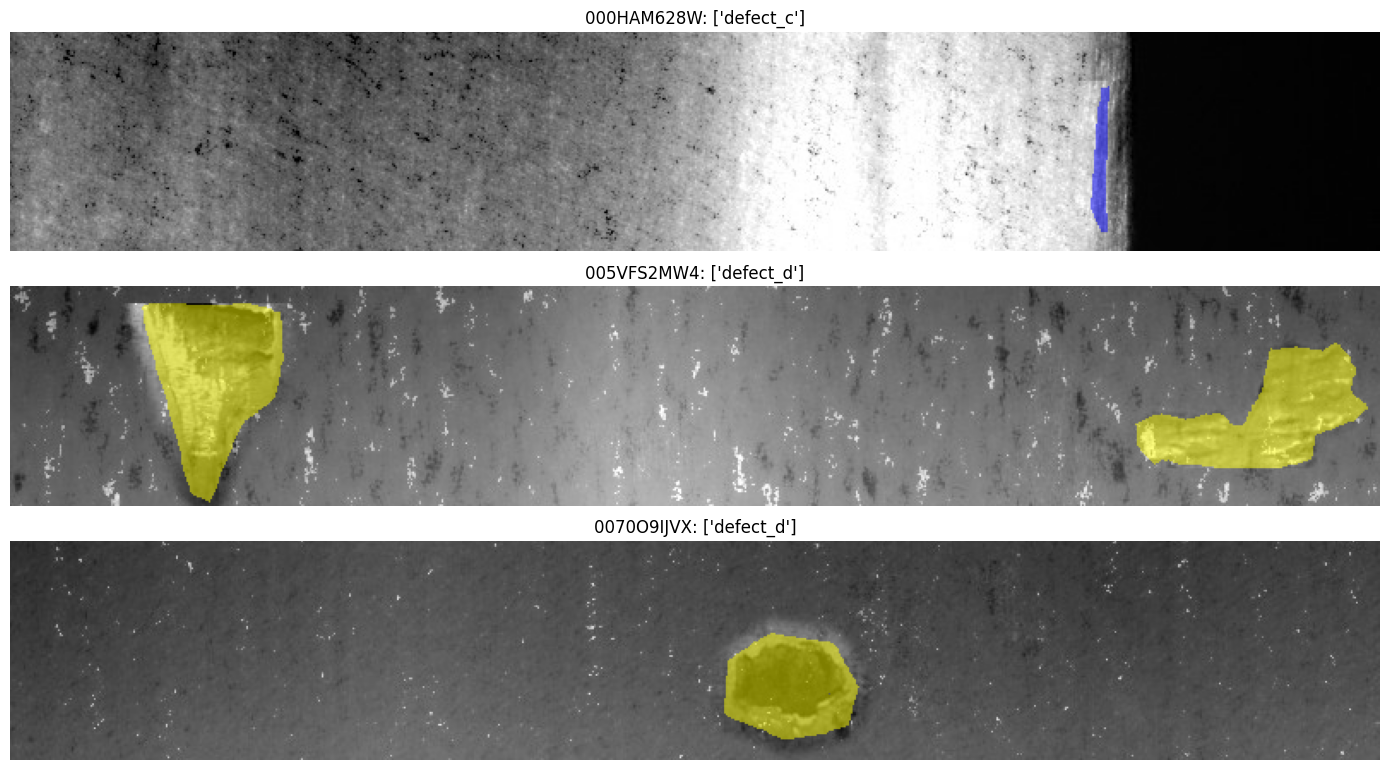

In [4]:
img_ids = sorted(train_paths)
rle_map = defaultdict(lambda: [[] for _ in range(NC)])
for r in pos_df.itertuples():
    if r.img in train_paths and r.defect_type in CLS2IDX:
        rle_map[r.img][CLS2IDX[r.defect_type]].append(r.mask_rle)
rle_map = dict(rle_map)   # plain dict: picklable for DataLoader workers

labels = np.zeros((len(img_ids), NC), dtype=np.uint8)
for i, k in enumerate(img_ids):
    if k in rle_map:
        labels[i] = [len(v) > 0 for v in rle_map[k]]

print('images with no defect :', int((labels.sum(1) == 0).sum()), '/', len(img_ids))
print('images per class      :', dict(zip(CLASSES, labels.sum(0).tolist())))
print('images with >1 class  :', int((labels.sum(1) > 1).sum()))
print('class co-occurrence (images):')
print(pd.DataFrame(labels.T.astype(int) @ labels.astype(int), index=CLASSES, columns=CLASSES))

try:
    import matplotlib.pyplot as plt
    show = [k for k in img_ids if k in rle_map][:3]
    fig, axes = plt.subplots(len(show), 1, figsize=(14, 2.6 * len(show)))
    axes = np.atleast_1d(axes)
    colors = np.array([[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0]] * 3, dtype=np.uint8)
    for ax, k in zip(axes, show):
        img = cv2.cvtColor(cv2.imread(train_paths[k], cv2.IMREAD_GRAYSCALE), cv2.COLOR_GRAY2RGB)
        for c in range(NC):
            for rle in rle_map[k][c]:
                m = rle_decode(rle, img.shape[:2]).astype(bool)
                img[m] = (0.5 * img[m] + 0.5 * colors[c]).astype(np.uint8)
        present = [CLASSES[c] for c in range(NC) if rle_map[k][c]]
        ax.imshow(img); ax.set_title(f'{k}: {present}'); ax.axis('off')
    plt.tight_layout(); plt.show()
except Exception as e:
    print('visualisation skipped:', e)

## 4. Stratified train / validation split
Stratify on the combination of classes present so rare defect types appear in validation.

In [6]:
combo = np.array([''.join(map(str, l)) for l in labels])
cnt = Counter(combo)
strat = np.array([c if cnt[c] >= CFG['n_folds'] else 'rare' for c in combo])
skf = StratifiedKFold(n_splits=CFG['n_folds'], shuffle=True, random_state=CFG['seed'])
tr_idx, va_idx = next(skf.split(img_ids, strat))
train_ids = [img_ids[i] for i in tr_idx]
val_ids = [img_ids[i] for i in va_idx]
print('train:', len(train_ids), '| val:', len(val_ids))
print('val images per class:', dict(zip(CLASSES, labels[va_idx].sum(0).tolist())))

train: 9114 | val: 2279
val images per class: {'defect_a': 216, 'defect_b': 62, 'defect_c': 821, 'defect_d': 341}


## 5. Dataset & augmentations
Grayscale input (1 channel). Train: random width crop (biased towards defects), flips, brightness/contrast.

In [8]:
MEAN, STD = 0.449, 0.226

def read_gray(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise IOError(f'cannot read {path}')
    return img

class DefectDataset(Dataset):
    def __init__(self, ids, paths, rle_map=None, train=False, crop_w=None):
        self.ids, self.paths, self.rle_map = ids, paths, rle_map
        self.train, self.crop_w = train, crop_w

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        k = self.ids[i]
        img = read_gray(self.paths[k])
        oh, ow = img.shape
        mask = np.zeros((NC, oh, ow), dtype=np.uint8)
        if self.rle_map is not None and k in self.rle_map:
            for c in range(NC):
                for rle in self.rle_map[k][c]:
                    mask[c] |= rle_decode(rle, (oh, ow))
        if (oh, ow) != (H, W):   # bring odd-sized images to the working size
            img = cv2.resize(img, (W, H), interpolation=cv2.INTER_LINEAR)
            mask = np.stack([cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST) for m in mask])

        if self.train:
            img, mask = self.augment(img, mask)

        x = torch.from_numpy(((img.astype(np.float32) / 255.0 - MEAN) / STD)[None])
        y = torch.from_numpy(mask.astype(np.float32))
        return x, y, i, oh, ow

    def augment(self, img, mask):
        if self.crop_w and W > self.crop_w:
            cols = np.where(mask.any(axis=(0, 1)))[0]
            if len(cols) and random.random() < 0.6:   # centre the crop on a defect column
                cx = int(random.choice(cols))
                x0 = int(np.clip(cx - self.crop_w // 2 + random.randint(-self.crop_w // 4, self.crop_w // 4),
                                 0, W - self.crop_w))
            else:
                x0 = random.randint(0, W - self.crop_w)
            img, mask = img[:, x0:x0 + self.crop_w], mask[:, :, x0:x0 + self.crop_w]
        if random.random() < 0.5:
            img, mask = img[:, ::-1], mask[:, :, ::-1]
        if random.random() < 0.5:
            img, mask = img[::-1], mask[:, ::-1]
        if random.random() < 0.5:
            alpha, beta = random.uniform(0.8, 1.2), random.uniform(-20, 20)
            img = np.clip(img.astype(np.float32) * alpha + beta, 0, 255)
        return np.ascontiguousarray(img), np.ascontiguousarray(mask)

# Oversample images that contain rare classes (weight = largest boost among the classes present)
boost = np.array([CFG['rare_boost'].get(c, 1.0) for c in CLASSES])
sample_w = np.maximum(1.0, (labels[tr_idx] * boost).max(axis=1))
sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double), num_samples=len(train_ids),
                                replacement=True)
print('sampling weights:', dict(Counter(sample_w.tolist())))

# Persistent training workers are forked once; validation/test images load in the main process (num_workers=0),
# which keeps CPU RAM flat over a long run.
train_loader = DataLoader(DefectDataset(train_ids, train_paths, rle_map, train=True, crop_w=CFG['crop_w']),
                          batch_size=CFG['batch_size'], sampler=sampler, drop_last=True,
                          num_workers=CFG['num_workers'], persistent_workers=CFG['num_workers'] > 0)
loader_kw = dict(num_workers=0)
val_loader = DataLoader(DefectDataset(val_ids, train_paths, rle_map),
                        batch_size=8, shuffle=False, **loader_kw)
xb, yb, *_ = next(iter(train_loader))
print('batch:', tuple(xb.shape), tuple(yb.shape))

sampling weights: {1.0: 8032, 3.0: 251, 1.5: 831}
batch: (8, 1, 128, 512) (8, 4, 128, 512)


## 6. Models
- **ResNetUNet**: torchvision ResNet encoder (ImageNet weights, first conv adapted to 1 channel by summing RGB filters) + U-Net decoder.
- **ScratchUNet**: classic U-Net, randomly initialised.

Output head: 4 independent **sigmoid** channels (multi-label) because defect classes can co-occur.

In [13]:
class ConvBlock(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class DecoderBlock(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = ConvBlock(cin + cskip, cout)

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)

def pad32(x):
    h, w = x.shape[-2:]
    ph, pw = (32 - h % 32) % 32, (32 - w % 32) % 32
    if ph or pw:
        x = F.pad(x, (0, pw, 0, ph), mode='reflect')
    return x, h, w

class ResNetUNet(nn.Module):
    def __init__(self, arch='resnet34', n_classes=4, pretrained=True):
        super().__init__()
        enc = None
        if pretrained:
            try:
                enc = getattr(torchvision.models, arch)(weights='DEFAULT')
                print(f'{arch}: ImageNet weights loaded')
            except Exception as e:
                print(f'{arch}: could not load pretrained weights ({e}); using random init')
        if enc is None:
            enc = getattr(torchvision.models, arch)(weights=None)
        conv1 = nn.Conv2d(1, 64, 7, stride=2, padding=3, bias=False)
        conv1.weight.data = enc.conv1.weight.data.sum(dim=1, keepdim=True)   # RGB -> grayscale filters
        self.stem = nn.Sequential(conv1, enc.bn1, enc.relu)                  # 1/2, 64
        self.pool = enc.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = enc.layer1, enc.layer2, enc.layer3, enc.layer4
        self.dec4 = DecoderBlock(512, 256, 256)
        self.dec3 = DecoderBlock(256, 128, 128)
        self.dec2 = DecoderBlock(128, 64, 64)
        self.dec1 = DecoderBlock(64, 64, 32)
        self.dec0 = DecoderBlock(32, 0, 16)
        self.head = nn.Conv2d(16, n_classes, 3, padding=1)

    def forward(self, x):
        x, h, w = pad32(x)
        x0 = self.stem(x)                    # 1/2
        x1 = self.layer1(self.pool(x0))      # 1/4
        x2 = self.layer2(x1)                 # 1/8
        x3 = self.layer3(x2)                 # 1/16
        x4 = self.layer4(x3)                 # 1/32
        d = self.dec4(x4, x3)
        d = self.dec3(d, x2)
        d = self.dec2(d, x1)
        d = self.dec1(d, x0)
        d = self.dec0(d)
        return self.head(d)[..., :h, :w]

class ScratchUNet(nn.Module):
    def __init__(self, n_classes=4, base=32):
        super().__init__()
        ch = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc = nn.ModuleList([ConvBlock(1, ch[0])] + [ConvBlock(ch[i - 1], ch[i]) for i in range(1, 5)])
        self.dec = nn.ModuleList([DecoderBlock(ch[i], ch[i - 1], ch[i - 1]) for i in range(4, 0, -1)])
        self.head = nn.Conv2d(ch[0], n_classes, 1)

    def forward(self, x):
        x, h, w = pad32(x)
        skips = []
        for i, block in enumerate(self.enc):
            x = block(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()
        for block in self.dec:
            x = block(x, skips.pop())
        return self.head(x)[..., :h, :w]

class ScaledInput(nn.Module):
    """Upsample the input before the network and bring the logits back to the input size."""
    def __init__(self, net, scale):
        super().__init__()
        self.net, self.scale = net, scale

    def forward(self, x):
        h, w = x.shape[-2:]
        x = F.interpolate(x, scale_factor=self.scale, mode='bilinear', align_corners=False)
        return F.interpolate(self.net(x), size=(h, w), mode='bilinear', align_corners=False)

class SegFormerSeg(nn.Module):
    """Hugging Face SegFormer (MiT encoder + all-MLP decoder); logits come out at 1/4 resolution and are upsampled."""
    DEPTHS = {'b0': [2, 2, 2, 2], 'b1': [2, 2, 2, 2], 'b2': [3, 4, 6, 3], 'b3': [3, 4, 18, 3]}

    def __init__(self, variant='b2', n_classes=4, pretrained=True):
        super().__init__()
        from transformers import SegformerConfig, SegformerForSemanticSegmentation
        self.net = None
        if pretrained:
            try:
                self.net = SegformerForSemanticSegmentation.from_pretrained(
                    f'nvidia/mit-{variant}', num_labels=n_classes, ignore_mismatched_sizes=True)
                print(f'mit-{variant}: ImageNet weights loaded')
            except Exception as e:
                print(f'mit-{variant}: could not load pretrained weights ({e}); using random init')
        if self.net is None:
            small = variant in ('b0', 'b1')
            cfg = SegformerConfig(num_labels=n_classes, depths=self.DEPTHS[variant],
                                  hidden_sizes=[32, 64, 160, 256] if variant == 'b0' else [64, 128, 320, 512],
                                  decoder_hidden_size=256 if small else 768)
            self.net = SegformerForSemanticSegmentation(cfg)

    def forward(self, x):
        h, w = x.shape[-2:]
        logits = self.net(pixel_values=x.expand(-1, 3, -1, -1)).logits   # grayscale -> 3 identical channels
        return F.interpolate(logits, size=(h, w), mode='bilinear', align_corners=False)

    def head_parameters(self):
        return list(self.net.decode_head.parameters())

def build_model(name):
    if name.startswith('segformer_'):
        net = SegFormerSeg(name.split('_')[1], NC, pretrained=CFG['pretrained'])
    elif name == 'unet_scratch':
        net = ScratchUNet(NC)
    elif name in ('unet_resnet34', 'unet_resnet18'):
        net = ResNetUNet(name.split('_')[1], NC, pretrained=CFG['pretrained'])
    else:
        raise ValueError(name)
    return ScaledInput(net, CFG['scale']) if CFG['scale'] != 1 else net

## 7. Loss and competition metric
**Loss** = BCE + soft Dice.

**Metric (local re-implementation)** over every (image, class) pair, `FP` = predicted masks on empty pairs:
- lenient: `0.7 * Dice averaged over pairs with a true defect + 0.3 * (1 - FP / #empty pairs)`
- strict: same, but FP masks also count as Dice = 0 in the Dice average

Run 1 scored 0.647 lenient vs 0.597 on the leaderboard, roughly midway to strict, so post-processing is tuned on
`score = (lenient + strict) / 2`.

Post-processing per class: pixel threshold `t`, then drop the whole mask if its area < `min_area` or its maximum
probability < `gate`. For speed, validation never stores probability maps: for every threshold we accumulate
predicted-pixel counts, intersections and the max probability per (image, class), so the full
threshold × area × gate grid is searched on these counts in seconds.

In [12]:
class BCEDiceLoss(nn.Module):
    def forward(self, logits, target):
        bce = F.binary_cross_entropy_with_logits(logits, target)
        p = torch.sigmoid(logits)
        inter = (p * target).sum((0, 2, 3))
        den = p.sum((0, 2, 3)) + target.sum((0, 2, 3))
        dice = 1 - (2 * inter + 1) / (den + 1)
        return bce + dice.mean()

THRESHOLDS = np.round(np.arange(0.30, 0.81, 0.05), 2)
AREAS = np.unique((H * W * np.array([0, .0005, .001, .002, .003, .005, .0075, .01, .015, .02])).astype(int))
GATES = np.array([0.0, 0.5, 0.6, 0.7, 0.8, 0.9])

class StatAccumulator:
    def __init__(self):
        self.P, self.I, self.G, self.MX = [], [], [], []

    @torch.no_grad()
    def update(self, probs, masks):
        gt = masks > 0.5
        P, I = [], []
        for t in THRESHOLDS:
            b = probs > float(t)
            P.append(b.sum((2, 3)))
            I.append((b & gt).sum((2, 3)))
        self.P.append(torch.stack(P, -1).cpu())
        self.I.append(torch.stack(I, -1).cpu())
        self.G.append(gt.sum((2, 3)).cpu())
        self.MX.append(probs.amax((2, 3)).float().cpu())

    def arrays(self):   # P, I: [N, C, T]   G, MX: [N, C]
        cat = lambda xs: torch.cat(xs).numpy().astype(np.float64)
        return cat(self.P), cat(self.I), cat(self.G), cat(self.MX)

def metric_from_totals(D, FP, n_pos, n_emp):
    """D = summed Dice over positive pairs, FP = #predicted masks on empty pairs -> (lenient, strict, score)."""
    lenient = 0.7 * D / n_pos + 0.3 * (1 - FP / n_emp)
    strict = 0.7 * D / (n_pos + FP) + 0.3 * (1 - FP / n_emp)
    return lenient, strict, (lenient + strict) / 2

def mask_terms(P, I, G, MX, area, gate):
    """P, I: [N, T], G, MX: [N] -> kept-mask flags [N, T], Dice sum over positive pairs [T], FP count [T]."""
    keep = (P > 0) & (P >= area) & (MX[:, None] >= gate)
    pos = G > 0
    dice = 2 * I * keep / np.maximum(P * keep + G[:, None], 1)
    return keep, dice[pos].sum(0), keep[~pos].sum(0).astype(np.float64)

def tune_postprocess(P, I, G, MX):
    """Pick (threshold, min_area, gate) per class maximising `score` (coordinate ascent over classes)."""
    n_pos, n_emp = max((G > 0).sum(), 1), max((G == 0).sum(), 1)
    cands = []
    for c in range(NC):
        ds, fs, prm = [], [], []
        for a in AREAS:
            for g in GATES:
                _, d, f = mask_terms(P[:, c], I[:, c], G[:, c], MX[:, c], a, g)
                ds.append(d); fs.append(f)
                prm += [{'threshold': float(t), 'min_area': int(a), 'gate': float(g)} for t in THRESHOLDS]
        cands.append((np.concatenate(ds), np.concatenate(fs), prm))
    choice = [int(np.argmax(0.7 * d / n_pos - 0.3 * f / n_emp)) for d, f, _ in cands]   # lenient optimum
    for _ in range(4):
        for c in range(NC):
            D_rest = sum(cands[k][0][choice[k]] for k in range(NC) if k != c)
            F_rest = sum(cands[k][1][choice[k]] for k in range(NC) if k != c)
            score = metric_from_totals(D_rest + cands[c][0], F_rest + cands[c][1], n_pos, n_emp)[2]
            choice[c] = int(np.argmax(score))
    return [cands[c][2][choice[c]] for c in range(NC)]

def evaluate(P, I, G, MX, params):
    n_pos, n_emp = max((G > 0).sum(), 1), max((G == 0).sum(), 1)
    D = FP = 0.0
    f1s, accs = [], []
    for c, prm in enumerate(params):
        j = int(np.argmin(np.abs(THRESHOLDS - prm['threshold'])))
        keep, d, f = mask_terms(P[:, c, j:j + 1], I[:, c, j:j + 1], G[:, c], MX[:, c], prm['min_area'], prm['gate'])
        D += d[0]; FP += f[0]
        pred, true = keep[:, 0], G[:, c] > 0       # image-level presence classification
        tp, fp, fn = (pred & true).sum(), (pred & ~true).sum(), (~pred & true).sum()
        f1s.append(2 * tp / max(2 * tp + fp + fn, 1)); accs.append((pred == true).mean())
    lenient, strict, score = metric_from_totals(D, FP, n_pos, n_emp)
    return {'score': score, 'score_lenient': lenient, 'score_strict': strict, 'dice_pos': D / n_pos,
            'empty_acc': 1 - FP / n_emp, 'cls_f1_macro': float(np.mean(f1s)), 'cls_acc': float(np.mean(accs))}

In [14]:
# Q8 experiment: scratch vs ImageNet-pretrained ResNet-34 U-Net, 5 epochs, identical settings
CFG['scale'] = 1   # plain U-Net input, same for both models

def compound(logits, y):
    bce = F.binary_cross_entropy_with_logits(logits, y)
    p = torch.sigmoid(logits)
    dice = 1 - (2 * (p * y).sum() + 1) / (p.sum() + y.sum() + 1)
    return 0.5 * bce + 0.5 * dice

tr_loader = DataLoader(DefectDataset(train_ids, train_paths, rle_map, train=True, crop_w=512),
                       batch_size=16, shuffle=True, drop_last=True, num_workers=2)
tr_eval = DataLoader(DefectDataset(train_ids[:2000], train_paths, rle_map), batch_size=16, num_workers=2)
va_loader = DataLoader(DefectDataset(val_ids, train_paths, rle_map), batch_size=16, num_workers=2)

@torch.no_grad()
def loss_and_stats(model, loader, stats=False):
    model.eval(); tot = n = 0; acc = StatAccumulator()
    for x, y, *_ in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(x).float()
        tot += compound(logits, y).item() * len(x); n += len(x)
        if stats:
            acc.update(torch.sigmoid(logits), y)
    return tot / n, (acc.arrays() if stats else None)

results = {}
for name in ['unet_scratch', 'unet_resnet34']:
    torch.manual_seed(42)
    model = build_model(name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-2)
    scaler = torch.amp.GradScaler('cuda')
    for ep in range(1, 6):
        t0 = time.time(); model.train()
        for x, y, *_ in tr_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                logits = model(x)
            loss = compound(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tr_loss, _ = loss_and_stats(model, tr_eval)
        va_loss, (P, I, G, MX) = loss_and_stats(model, va_loader, stats=True)
        m = evaluate(P, I, G, MX, tune_postprocess(P, I, G, MX))
        print(f"{name} ep{ep} | train_loss {tr_loss:.4f} | val_loss {va_loss:.4f} | gap {va_loss - tr_loss:+.4f} | "
              f"dice+ {m['dice_pos']:.4f} | score {m['score']:.4f} | {time.time() - t0:.0f}s")
    results[name] = (m['score'], va_loss - tr_loss)
    del model, opt; gc.collect(); torch.cuda.empty_cache()

print('score improvement (pretrained - scratch): %+.4f' % (results['unet_resnet34'][0] - results['unet_scratch'][0]))
print('final gap  scratch %+.4f | pretrained %+.4f' % (results['unet_scratch'][1], results['unet_resnet34'][1]))


unet_scratch ep1 | train_loss 0.5322 | val_loss 0.5297 | gap -0.0024 | dice+ 0.1779 | score 0.3653 | 141s
unet_scratch ep2 | train_loss 0.4140 | val_loss 0.4065 | gap -0.0075 | dice+ 0.2168 | score 0.4084 | 143s
unet_scratch ep3 | train_loss 0.4150 | val_loss 0.4160 | gap +0.0009 | dice+ 0.2487 | score 0.4012 | 143s
unet_scratch ep4 | train_loss 0.3577 | val_loss 0.3450 | gap -0.0128 | dice+ 0.2630 | score 0.4373 | 144s
unet_scratch ep5 | train_loss 0.3104 | val_loss 0.3073 | gap -0.0031 | dice+ 0.2832 | score 0.4556 | 144s
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 213MB/s]


resnet34: ImageNet weights loaded
unet_resnet34 ep1 | train_loss 0.4608 | val_loss 0.4556 | gap -0.0052 | dice+ 0.2119 | score 0.3891 | 97s
unet_resnet34 ep2 | train_loss 0.3446 | val_loss 0.3437 | gap -0.0009 | dice+ 0.2274 | score 0.4312 | 96s
unet_resnet34 ep3 | train_loss 0.3308 | val_loss 0.3319 | gap +0.0011 | dice+ 0.2357 | score 0.4453 | 96s
unet_resnet34 ep4 | train_loss 0.3310 | val_loss 0.3325 | gap +0.0015 | dice+ 0.2460 | score 0.4449 | 96s
unet_resnet34 ep5 | train_loss 0.3129 | val_loss 0.3136 | gap +0.0007 | dice+ 0.3202 | score 0.4803 | 96s
score improvement (pretrained - scratch): +0.0247
final gap  scratch -0.0031 | pretrained +0.0007


## 8. Training (AMP, time-aware warmup + cosine LR, best-checkpoint selection, W&B)

In [9]:
def autocast():
    return torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP)

@torch.no_grad()
def forward_probs(model, x, tta=False):
    with autocast():
        p = torch.sigmoid(model(x).float())
        if tta:
            p += torch.sigmoid(model(x.flip(-1)).float()).flip(-1)
            p += torch.sigmoid(model(x.flip(-2)).float()).flip(-2)
            p /= 3
    return p

@torch.no_grad()
def run_validation(model, loader, tta=False):
    model.eval()
    acc = StatAccumulator()
    for x, y, *_ in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        acc.update(forward_probs(model, x, tta), y)
    return acc.arrays()

TOTAL_STEPS = CFG['epochs'] * len(train_loader)

def progress(step, t_start):
    """Fraction of training done: by step count or by wall-clock budget, whichever is further along."""
    return max(step / TOTAL_STEPS, (time.time() - t_start) / 60 / CFG['time_budget_min'])

def ram_gb():
    """(used, available) CPU RAM in GB."""
    try:
        import psutil
        vm = psutil.virtual_memory()
        return vm.used / 2**30, vm.available / 2**30
    except Exception:
        return float('nan'), float('inf')

def lr_at(p):
    """Linear warmup then cosine decay to 2% of the peak learning rate."""
    if p < CFG['warmup_frac']:
        return CFG['lr'] * max(p / CFG['warmup_frac'], 0.01)
    q = min((p - CFG['warmup_frac']) / (1 - CFG['warmup_frac']), 1.0)
    return CFG['lr'] * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * q)))

def train_one_epoch(model, loader, opt, scaler, loss_fn, step, t_start):
    model.train()
    total, n = 0.0, 0
    for x, y, *_ in loader:
        p = progress(step, t_start)
        if p >= 1:
            break
        for g in opt.param_groups:
            g['lr'] = lr_at(p) * g.get('lr_mult', 1.0)
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with autocast():
            logits = model(x)
        loss = loss_fn(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        step += 1
        total += loss.item() * len(x); n += len(x)
    return total / max(n, 1), step

wb = None
if CFG['use_wandb']:
    try:
        import wandb
        from kaggle_secrets import UserSecretsClient
        wandb.login(key=UserSecretsClient().get_secret('WANDB_API_KEY'))
        wb = wandb.init(project=CFG['wandb_project'], name=CFG['model_name'], config=CFG)
    except Exception as e:
        print('W&B disabled:', e)
        wb = None

model = build_model(CFG['model_name']).to(DEVICE)
if CFG['multi_gpu'] and torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)
print('parameters: %.1fM' % (sum(p.numel() for p in model.parameters()) / 1e6))

loss_fn = BCEDiceLoss()
core = model.module if isinstance(model, nn.DataParallel) else model
core = core.net if isinstance(core, ScaledInput) else core
head = core.head_parameters() if hasattr(core, 'head_parameters') else []
head_ids = {id(p) for p in head}
groups = [{'params': [p for p in model.parameters() if id(p) not in head_ids], 'lr_mult': 1.0}]
if head:
    groups.append({'params': head, 'lr_mult': CFG['head_lr_mult']})
opt = torch.optim.AdamW(groups, lr=CFG['lr'], weight_decay=CFG['weight_decay'])
try:
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

BEST_PATH = os.path.join(OUT_DIR, f"best_{CFG['model_name']}.pth")
best_score, best_epoch, history = -1.0, -1, []
step, t_start = 0, time.time()
for epoch in range(1, CFG['epochs'] + 1):
    t0 = time.time()
    tr_loss, step = train_one_epoch(model, train_loader, opt, scaler, loss_fn, step, t_start)
    p = progress(step, t_start)
    lr = opt.param_groups[0]['lr']
    if epoch == 1 or p >= CFG['val_from']:
        P, I, G, MX = run_validation(model, val_loader)
        params = tune_postprocess(P, I, G, MX)
        m = evaluate(P, I, G, MX, params)
        if m['score'] > best_score:
            best_score, best_epoch = m['score'], epoch
            state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
            torch.save(state, BEST_PATH)
        val_txt = (f"val score {m['score']:.4f} (lenient {m['score_lenient']:.4f}, strict {m['score_strict']:.4f}) | "
                   f"dice+ {m['dice_pos']:.4f} | empty acc {m['empty_acc']:.4f} | F1 {m['cls_f1_macro']:.3f}")
    else:
        m, val_txt = {}, 'no validation yet'
    gc.collect()
    used, free = ram_gb()
    history.append({'epoch': epoch, 'train_loss': tr_loss, 'lr': lr, 'ram_used_gb': used, **m})
    print(f"ep {epoch:02d} | loss {tr_loss:.4f} | {val_txt} | lr {lr:.1e} | "
          f"RAM {used:.1f} GB used, {free:.1f} GB free | {time.time() - t0:.0f}s")
    if wb is not None:
        wb.log({'epoch': epoch, 'train_loss': tr_loss, 'lr': lr, 'ram_used_gb': used,
                **{f'val_{k}': v for k, v in m.items()}})
    if p >= 1:
        print(f'schedule finished after {(time.time() - t_start) / 60:.0f} min')
        break
    if free < CFG['min_free_ram_gb']:
        print(f'WARNING: only {free:.1f} GB RAM free - stopping training early to keep the submission safe')
        break
print(f'best val score {best_score:.4f} at epoch {best_epoch} | training time {(time.time() - t_start) / 60:.1f} min')

# Shut down the persistent training workers before tuning and inference
del train_loader, xb, yb
gc.collect()
print('RAM after training: %.1f GB used, %.1f GB free' % ram_gb())

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2001289 (23f2001289-project) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


parameters: 7.8M


KeyboardInterrupt: 

## 9. Final post-processing tuning (best checkpoint + flip TTA)

In [ ]:
core = model.module if isinstance(model, nn.DataParallel) else model
core.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE))
P, I, G, MX = run_validation(model, val_loader, tta=True)
PARAMS = tune_postprocess(P, I, G, MX)
final = evaluate(P, I, G, MX, PARAMS)
print('validation with TTA:', {k: round(v, 4) for k, v in final.items()})
for c, prm in zip(CLASSES, PARAMS):
    print(f'  {c}: threshold={prm["threshold"]}, min_area={prm["min_area"]}, gate={prm["gate"]}')
with open(os.path.join(OUT_DIR, f"postprocess_{CFG['model_name']}.json"), 'w') as f:
    json.dump({'classes': CLASSES, 'params': PARAMS, 'val': final, 'shape': [H, W], 'rle_base': RLE_BASE}, f, indent=2)
pd.DataFrame(history).to_csv(os.path.join(OUT_DIR, f"history_{CFG['model_name']}.csv"), index=False)
if wb is not None:
    wb.summary.update({f'final_tta_{k}': v for k, v in final.items()})

## 10. Test inference → `submission.csv`

In [ ]:
sub_df['img'] = sub_df['image_id'].map(stem)
test_ids = [k for k in dict.fromkeys(sub_df['img']) if k in test_paths]
missing = sub_df['img'].nunique() - len(test_ids)
if missing:
    print(f'WARNING: {missing} test images listed in sample_submission were not found; they get empty masks.')
test_loader = DataLoader(DefectDataset(test_ids, test_paths), batch_size=8, shuffle=False, **loader_kw)

preds = {}
model.eval()
t0 = time.time()
for x, _, idx, oh, ow in test_loader:
    probs = forward_probs(model, x.to(DEVICE, non_blocking=True), tta=True).cpu().numpy()
    for b in range(len(idx)):
        k, h0, w0 = test_ids[int(idx[b])], int(oh[b]), int(ow[b])
        scale = (h0 * w0) / (H * W)
        for c in range(NC):
            pc = probs[b, c]
            if pc.shape != (h0, w0):
                pc = cv2.resize(pc, (w0, h0), interpolation=cv2.INTER_LINEAR)
            m = pc > PARAMS[c]['threshold']
            area = int(m.sum())
            keep = area > 0 and area >= PARAMS[c]['min_area'] * scale and pc.max() >= PARAMS[c]['gate']
            preds[(k, CLASSES[c])] = rle_encode(m) if keep else EMPTY_RLE
print(f'inference done in {time.time() - t0:.0f}s')

submission = pd.read_csv(SUB_CSV, dtype=str, keep_default_na=False)
submission['mask_rle'] = [preds.get((stem(i), str(d).strip()), EMPTY_RLE)
                          for i, d in zip(submission['image_id'], submission['defect_type'])]
submission.to_csv(os.path.join(OUT_DIR, 'submission.csv'), index=False)

# Sanity checks
chk = pd.read_csv(os.path.join(OUT_DIR, 'submission.csv'), dtype=str, keep_default_na=False)
assert list(chk.columns) == list(pd.read_csv(SUB_CSV, nrows=1).columns)
assert len(chk) == len(sub_df)
nonempty = chk['mask_rle'].str.strip() != ''
print('submission rows:', len(chk), '| non-empty masks:', int(nonempty.sum()))
print(chk[nonempty].groupby('defect_type').size())
print(chk.head())
if wb is not None:
    wb.finish()

In [4]:
# Milestone 4: questions 1-10 (code: scripts/milestone4_source.py on my milestone-4 branch)
import subprocess
from kaggle_secrets import UserSecretsClient
token = UserSecretsClient().get_secret('GITHUB_TOKEN')
subprocess.run('rm -rf /kaggle/working/repo', shell=True)
r = subprocess.run(['git', 'clone', '-q', '-b', 'milestone-4',
                    f'https://{token}@github.com/AYUSH9693291431/DL-GENAI-PROJECT.git', '/kaggle/working/repo'],
                   capture_output=True, text=True)
if r.returncode:
    raise RuntimeError('git clone failed: ' + r.stderr.replace(token, '***'))
%run /kaggle/working/repo/scripts/milestone4_source.py


train.csv: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
images: 1200 | image-class rows: 4800
groups merged into rare_other: combinations with fewer than 3 images -> 7 images
train: 960 | val: 240
defect_type
clean                         578
defect_c                      334
defect_d                       81
defect_c+defect_d              71
defect_a                       59
defect_b                       22
defect_a+defect_c              21
defect_a+defect_d              14
defect_a+defect_c+defect_d      7
defect_b+defect_d               3
defect_a+defect_b+defect_d      3
defect_a+defect_b               2
defect_b+defect_c+defect_d      2
defect_b+defect_c               2
defect_a+defect_b+defect_c      1 

(a) clean images: 578
(b) positive images per class: {'defect_a': 107, 'defect_b': 35, 'defect_c': 438, 'defect_d': 181}
(c) unique combination strings: 15
(d) largest / smallest group: 578 / 1

Answer: 578; 107, 35, 438, 181; 15; 578, 1
defect

100%|██████████| 83.3M/83.3M [00:00<00:00, 206MB/s] 


resnet34: ImageNet weights loaded


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2001289 (23f2001289-project) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


epoch 1 | train loss 1.6162 | val loss 1.6313 | val score 0.2212 | 16s
epoch 2 | train loss 1.3577 | val loss 1.2548 | val score 0.3184 | 13s
epoch 3 | train loss 1.1563 | val loss 1.1085 | val score 0.4059 | 13s
epoch 4 | train loss 1.0726 | val loss 1.0492 | val score 0.4513 | 13s
epoch 5 | train loss 1.0331 | val loss 1.0355 | val score 0.5165 | 13s
epoch 6 | train loss 1.0164 | val loss 1.0221 | val score 0.5204 | 14s


epoch,▁▂▄▅▇█
lr,█▇▆▃▂▁
train_loss,█▅▃▂▁▁
val_empty_acc,▁▆██▇█
val_fg_dice,▁▁▄▅██
val_fp_score,▁█████
val_loss,█▄▂▁▁▁
val_score,▁▃▅▆██
epoch,6
lr,0
train_loss,1.01645


... (10 outputs left out)

resnet34: ImageNet weights loaded


epoch 1 | train loss 1.4714 | val loss 1.3179 | val score 0.3381 | 14s
epoch 2 | train loss 1.1630 | val loss 1.1480 | val score 0.3002 | 14s
epoch 3 | train loss 1.0304 | val loss 1.0438 | val score 0.3979 | 14s
epoch 4 | train loss 0.9500 | val loss 0.9435 | val score 0.4767 | 14s
epoch 5 | train loss 0.8638 | val loss 0.9069 | val score 0.4930 | 14s
epoch 6 | train loss 0.8330 | val loss 0.8979 | val score 0.4455 | 14s


epoch,▁▂▄▅▇█
lr,▁▁▁▁▁▁
train_loss,█▅▃▂▁▁
val_empty_acc,▁█▆▆▆▇
val_fg_dice,▄▁▅▇█▆
val_fp_score,▁█▅▇▇█
val_loss,█▅▃▂▁▁
val_score,▂▁▅▇█▆
epoch,6
lr,0.0003
train_loss,0.83299


     epoch  val_score  val_fg_dice  val_fp_score  val_empty_acc
R0     5.0     0.4343       0.2043        0.9970         0.9196
R0b    6.0     0.4870       0.2958        0.9871         0.8255
R1     6.0     0.5204       0.3252        0.9990         0.9295
R2     5.0     0.4930       0.2914        0.9979         0.8948 

(a) best official score: R0 0.434, R0b 0.487, R1 0.520, R2 0.493
(b) noise band 0.053 | gain R1 0.086 | gain R2 0.059
(c) R1 gain > 2x noise: no | R2 gain > 2x noise: no
(d) clean-image false-alarm rate: R0 8.0% | R2 10.5%

Answer (a; b; c; d): 0.434, 0.487, 0.520, 0.493; 0.053, 0.086, 0.059; no, no; 8.0%, 10.5%


In [5]:
# Milestone 4, Q10 (OFAT): runs on its own, using the code in my repo (scripts/milestone4_source.py)
import math, os, subprocess, torch
import pandas as pd
from kaggle_secrets import UserSecretsClient

REPO = '/kaggle/working/repo'
token = UserSecretsClient().get_secret('GITHUB_TOKEN')
subprocess.run(['rm', '-rf', REPO])
r = subprocess.run(['git', 'clone', '-q', '-b', 'milestone-4',
                    f'https://{token}@github.com/AYUSH9693291431/DL-GENAI-PROJECT.git', REPO],
                   capture_output=True, text=True)
if r.returncode:
    raise RuntimeError('git clone failed: ' + r.stderr.replace(token, '***'))

src = open(REPO + '/scripts/milestone4_source.py').read()
cut = lambda a, b: '#' + src.split(a)[1].split(b)[0]
exec(src.split('# %% [markdown]\n# ## Q1')[0])                                    # data, subset, split
exec(cut('# %% [markdown]\n# ## Training setup', '# %% [markdown]\n# ## Q8'))     # dataset, validate, run_experiment

# R1 = the Q8 run (warmup + cosine, seed 42): reuse its saved history, or train it again if it is gone
q8_csv = os.path.join(OUT_DIR, 'm4_q8_history.csv')
hist8 = pd.read_csv(q8_csv) if os.path.exists(q8_csv) else run_experiment('m4_q8_baseline_6ep', epochs=6)
exec('#' + src.split('# %% [markdown]\n# ## Q10')[1])                             # R0, R0b, R2 + answers


train.csv: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
images: 1200 | image-class rows: 4800
groups merged into rare_other: combinations with fewer than 3 images -> 7 images
train: 960 | val: 240
device: cuda | model code from: /kaggle/working/repo/src
Sampler weights on the training images (group size -> weight):
                            size  first
group                                  
clean                        462  1.000
defect_c                     267  1.315
defect_d                      65  2.666
defect_c+defect_d             57  2.847
defect_a                      47  3.135
defect_b                      18  5.000
defect_a+defect_c             17  5.000
defect_a+defect_d             11  5.000
defect_a+defect_c+defect_d     6  5.000
defect_a+defect_b              2  5.000
defect_a+defect_b+defect_d     2  5.000
defect_b+defect_d              2  5.000
defect_b+defect_c              2  5.000
defect_a+defect_b+defect_c     1  5.000
defect_b

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


resnet34: ImageNet weights loaded


epoch 1 | train loss 1.4737 | val loss 1.3096 | val score 0.2689 | 15s
epoch 2 | train loss 1.1845 | val loss 1.1761 | val score 0.2981 | 14s
epoch 3 | train loss 1.0749 | val loss 1.0742 | val score 0.3000 | 14s
epoch 4 | train loss 1.0205 | val loss 1.0065 | val score 0.3772 | 14s
epoch 5 | train loss 0.9893 | val loss 0.9745 | val score 0.4343 | 14s
epoch 6 | train loss 0.9545 | val loss 0.9544 | val score 0.4198 | 14s


epoch,▁▂▄▅▇█
lr,▁▁▁▁▁▁
train_loss,█▄▃▂▁▁
val_empty_acc,▁███▇▇
val_fg_dice,▃▁▁▅█▇
val_fp_score,▁███▅▄
val_loss,█▅▃▂▁▁
val_score,▁▂▂▆█▇
epoch,6
lr,0.0003
train_loss,0.95454


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


... (4 outputs left out)

resnet34: ImageNet weights loaded


epoch 1 | train loss 1.4714 | val loss 1.3179 | val score 0.3381 | 14s
epoch 2 | train loss 1.1630 | val loss 1.1480 | val score 0.3002 | 14s
epoch 3 | train loss 1.0304 | val loss 1.0438 | val score 0.3979 | 14s
epoch 4 | train loss 0.9500 | val loss 0.9435 | val score 0.4767 | 14s
epoch 5 | train loss 0.8638 | val loss 0.9069 | val score 0.4930 | 14s
epoch 6 | train loss 0.8330 | val loss 0.8979 | val score 0.4455 | 14s


epoch,▁▂▄▅▇█
lr,▁▁▁▁▁▁
train_loss,█▅▃▂▁▁
val_empty_acc,▁█▆▆▆▇
val_fg_dice,▄▁▅▇█▆
val_fp_score,▁█▅▇▇█
val_loss,█▅▃▂▁▁
val_score,▂▁▅▇█▆
epoch,6
lr,0.0003
train_loss,0.83299


     epoch  val_score  val_fg_dice  val_fp_score  val_empty_acc
R0     5.0     0.4343       0.2043        0.9970         0.9196
R0b    6.0     0.4870       0.2958        0.9871         0.8255
R1     6.0     0.5204       0.3252        0.9990         0.9295
R2     5.0     0.4930       0.2914        0.9979         0.8948 

(a) best official score: R0 0.434, R0b 0.487, R1 0.520, R2 0.493
(b) noise band 0.053 | gain R1 0.086 | gain R2 0.059
(c) R1 gain > 2x noise: no | R2 gain > 2x noise: no
(d) clean-image false-alarm rate: R0 8.0% | R2 10.5%

Answer (a; b; c; d): 0.434, 0.487, 0.520, 0.493; 0.053, 0.086, 0.059; no, no; 8.0%, 10.5%


In [8]:
# Milestone 4: validation error analysis of my best model (SegFormer-B2), using src/error_analysis.py
import glob, json, os, subprocess
from kaggle_secrets import UserSecretsClient

REPO = '/kaggle/working/repo'
token = UserSecretsClient().get_secret('GITHUB_TOKEN')
subprocess.run(['rm', '-rf', REPO])
r = subprocess.run(['git', 'clone', '-q', '-b', 'milestone-4',
                    f'https://{token}@github.com/AYUSH9693291431/DL-GENAI-PROJECT.git', REPO],
                   capture_output=True, text=True)
if r.returncode:
    raise RuntimeError('git clone failed: ' + r.stderr.replace(token, '***'))

ckpt = glob.glob('/kaggle/input/**/best_segformer_b2.pth', recursive=True)[0]
pp = glob.glob('/kaggle/input/**/postprocess_segformer_b2.json', recursive=True)[0]
data_dir = os.path.dirname(glob.glob('/kaggle/input/**/train.csv', recursive=True)[0])
print(ckpt, pp, data_dir, sep='\n')

cfg = json.load(open(pp))                       # the notebook's settings file has no model name / scale
cfg.setdefault('model', 'segformer_b2'); cfg.setdefault('scale', 2)
json.dump(cfg, open('/kaggle/working/postprocess_segformer_b2.json', 'w'), indent=2)

!python {REPO}/src/error_analysis.py --data-dir {data_dir} --checkpoint {ckpt} \
    --postprocess /kaggle/working/postprocess_segformer_b2.json --out /kaggle/working/error_analysis.csv


IndexError: list index out of range

In [9]:
# What model files does this notebook have access to?
!find -L /kaggle/input /kaggle/working -maxdepth 6 \( -name "*.pth" -o -name "postprocess_*.json" \) 2>/dev/null
!ls /kaggle/input


/kaggle/working/best_m4_q8_baseline_6ep.pth
/kaggle/working/best_m4_q10_R2_sqrt_sampler.pth
/kaggle/working/best_m4_q10_R0_constant.pth
/kaggle/working/best_m4_q10_R0b_seed7.pth
competitions  notebooks


In [10]:
!find -L /kaggle/input/notebooks | head -40


/kaggle/input/notebooks
/kaggle/input/notebooks/ayushraj372004
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026/__notebook__.ipynb
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026/__output__.json
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026/__results__.html
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026/__results___files
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026/__results___files/__results___7_1.png
/kaggle/input/notebooks/ayushraj372004/dl-23f2001289-notebook-t32026/custom.css


In [1]:
# Milestone 4: validation error analysis of the Q8 baseline (code: scripts/milestone4_source.py)
import math, os, subprocess, torch
import pandas as pd
from kaggle_secrets import UserSecretsClient

REPO = '/kaggle/working/repo'
token = UserSecretsClient().get_secret('GITHUB_TOKEN')
subprocess.run(['rm', '-rf', REPO])
r = subprocess.run(['git', 'clone', '-q', '-b', 'milestone-4',
                    f'https://{token}@github.com/AYUSH9693291431/DL-GENAI-PROJECT.git', REPO],
                   capture_output=True, text=True)
if r.returncode:
    raise RuntimeError('git clone failed: ' + r.stderr.replace(token, '***'))

src = open(REPO + '/scripts/milestone4_source.py').read()
cut = lambda a, b: '#' + src.split(a)[1].split(b)[0]
exec(src.split('# %% [markdown]\n# ## Q1')[0])                                    # data, subset, split
exec(cut('# %% [markdown]\n# ## Training setup', '# %% [markdown]\n# ## Q8'))     # dataset + model code
exec('#' + src.split('# %% [markdown]\n# ## Validation error analysis')[1])        # error analysis


train.csv: /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
images: 1200 | image-class rows: 4800
groups merged into rare_other: combinations with fewer than 3 images -> 7 images
train: 960 | val: 240
device: cuda | model code from: /kaggle/working/repo/src
Q8 checkpoint not found, retraining the Q8 baseline first
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 185MB/s] 


resnet34: ImageNet weights loaded


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f2001289 (23f2001289-project) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


epoch 1 | train loss 1.6162 | val loss 1.6313 | val score 0.2212 | 17s
epoch 2 | train loss 1.3577 | val loss 1.2548 | val score 0.3184 | 13s
epoch 3 | train loss 1.1563 | val loss 1.1085 | val score 0.4059 | 13s
epoch 4 | train loss 1.0726 | val loss 1.0492 | val score 0.4513 | 13s
epoch 5 | train loss 1.0331 | val loss 1.0355 | val score 0.5165 | 14s
epoch 6 | train loss 1.0164 | val loss 1.0221 | val score 0.5204 | 13s


epoch,▁▂▄▅▇█
lr,█▇▆▃▂▁
train_loss,█▅▃▂▁▁
val_empty_acc,▁▆██▇█
val_fg_dice,▁▁▄▅██
val_fp_score,▁█████
val_loss,█▄▂▁▁▁
val_score,▁▃▅▆██
epoch,6
lr,0
train_loss,1.01645


          true_defects  hits  missed  false_alarms  dice_on_hits  median_area_hit  median_area_missed  boundary_share_of_hit_errors
defect_a          21.0   0.0    21.0           0.0           NaN              NaN               763.0                         0.000
defect_b           7.0   0.0     7.0           0.0           NaN              NaN               652.0                         0.000
defect_c          87.0  66.0    21.0          42.0         0.469           2850.0              1059.0                         0.215
defect_d          37.0  32.0     5.0          15.0         0.578           6000.0              1656.0                         0.229
share of lost Dice caused by missed defects: 52.6%

all classes: true defects 152 | hits 98 | missed 54 | false alarms 57 | mean Dice on hits 0.504 | boundary share of hit errors 22.0%
